# Q1a

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Transpose so that rows are cells and columns are genes.
counts = pd.read_csv("pbmc_6Kcells_500genes.txt", sep="\t", index_col=0).T

library_sizes = counts.sum(axis=1)
median_library_size = library_sizes.median()
normalized = counts.div(library_sizes, axis=0) * median_library_size
log_expression = np.log1p(normalized)

print(f"{counts.shape[0]:,} cells and {counts.shape[1]} genes")
print(f"Median library size: {median_library_size:,.0f}")

6,825 cells and 500 genes
Median library size: 2,810


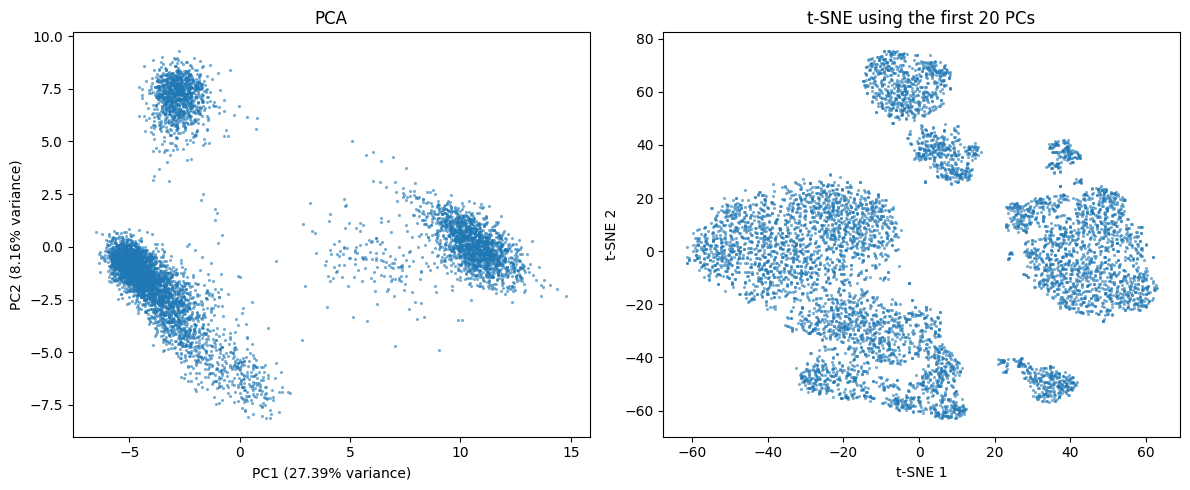

In [33]:
pca = PCA(svd_solver="full")
pc_scores = pca.fit_transform(log_expression)

embedding = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42,
).fit_transform(pc_scores[:, :20])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(pc_scores[:, 0], pc_scores[:, 1], s=5, alpha=0.6, linewidths=0)
axes[0].set(
    title="PCA",
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)",
)
axes[1].scatter(embedding[:, 0], embedding[:, 1], s=5, alpha=0.6, linewidths=0)
axes[1].set(title="t-SNE using the first 20 PCs", xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout()
plt.show()

## Q1b

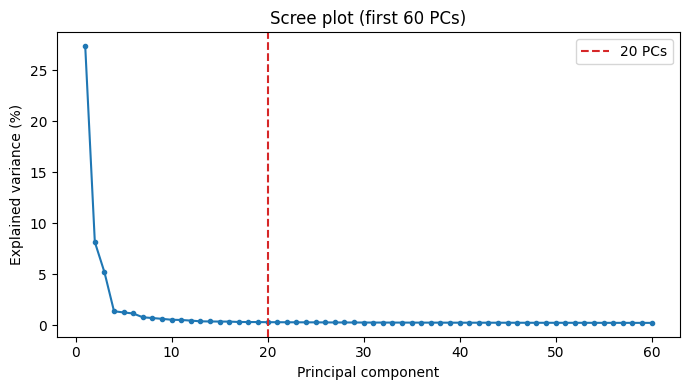

Variance explained by 20 PCs: 50.62%
Variance explained by PC 20: 0.28%


In [34]:
variance_ratio = pca.explained_variance_ratio_

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, 61), 100 * variance_ratio[:60], marker="o", markersize=3)
plt.axvline(20, color="tab:red", linestyle="--", label="20 PCs")
plt.title("Scree plot (first 60 PCs)")
plt.xlabel("Principal component")
plt.ylabel("Explained variance (%)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Variance explained by 20 PCs: {100 * variance_ratio[:20].sum():.2f}%")
print(f"Variance explained by PC 20: {100 * variance_ratio[19]:.2f}%")

20 PCs is a reasonable choice for an initial visualization, although it is not a clear optimal cutoff. The scree plot drops sharply over the first few PCs and then levels off, with no distinct elbow at 20. The first 20 PCs explain 50.62% of the variance, and PC 20 alone explains only 0.28%.

Using 20 PCs keeps the main patterns and may reduce noise, but it also leaves out about half of the total variance, which could include useful biological differences. Therefore, 20 is an ok choice but might not be the best.

## Q2

I applied K-means to the first 20 PCs and compared K = 2–10 using the silhouette score. A higher score indicates more compact and better-separated clusters. 

In [35]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = pc_scores[:, :20]
k_values = range(2, 11)
scores = []
models = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    score = silhouette_score(X, model.labels_)
    models.append(model)
    scores.append(score)
    print(f"K = {k}: silhouette score = {score:.3f}")

best_index = np.argmax(scores)
best_k = list(k_values)[best_index]
cluster_ids = models[best_index].labels_ + 1
print(f"\nSelected K = {best_k}")

K = 2: silhouette score = 0.511
K = 3: silhouette score = 0.472
K = 4: silhouette score = 0.493
K = 5: silhouette score = 0.446
K = 6: silhouette score = 0.374
K = 7: silhouette score = 0.264
K = 8: silhouette score = 0.226
K = 9: silhouette score = 0.229
K = 10: silhouette score = 0.218

Selected K = 2


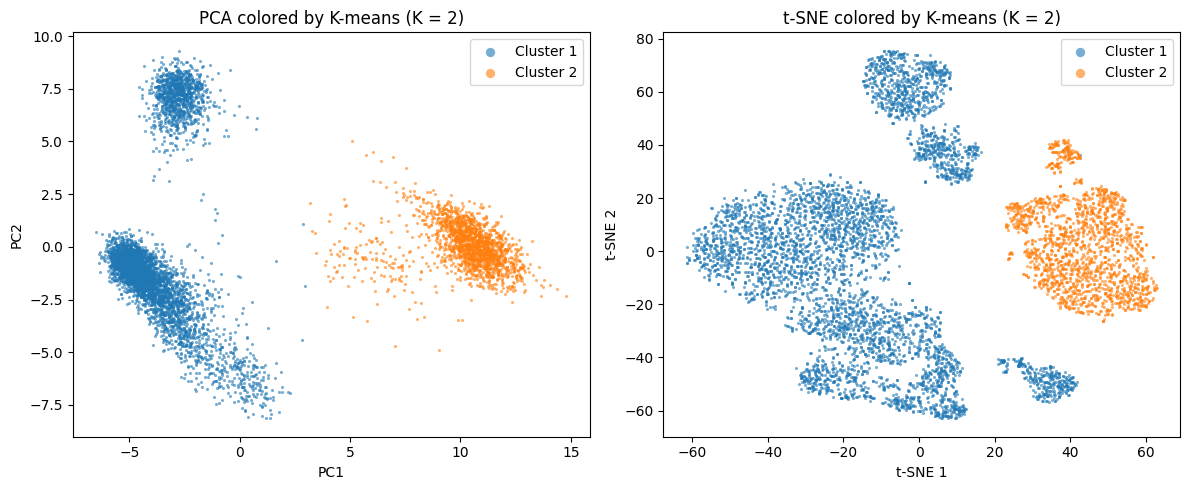

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = plt.get_cmap("tab10")

for cluster in range(1, best_k + 1):
    mask = cluster_ids == cluster
    axes[0].scatter(pc_scores[mask, 0], pc_scores[mask, 1],
                    s=5, alpha=0.6, linewidths=0,
                    color=colors(cluster - 1), label=f"Cluster {cluster}")
    axes[1].scatter(embedding[mask, 0], embedding[mask, 1],
                    s=5, alpha=0.6, linewidths=0,
                    color=colors(cluster - 1), label=f"Cluster {cluster}")

axes[0].set(title=f"PCA colored by K-means (K = {best_k})",
            xlabel="PC1", ylabel="PC2")
axes[1].set(title=f"t-SNE colored by K-means (K = {best_k})",
            xlabel="t-SNE 1", ylabel="t-SNE 2")
for ax in axes:
    ax.legend(markerscale=3)
plt.tight_layout()
plt.show()

I chose K = 2 because it had the highest silhouette score (0.511) among the values tested. This indicates that K = 2 produced the best-separated clusters among the tested values. The clustering was performed using the top 20 PCs for all 6,825 cells. Although the t-SNE plot shows more visually distinct groups, K-means assigns them to only two clusters because we chose K = 2, so these two clusters should not necessarily be interpreted as exactly two biological cell types.

## Q3

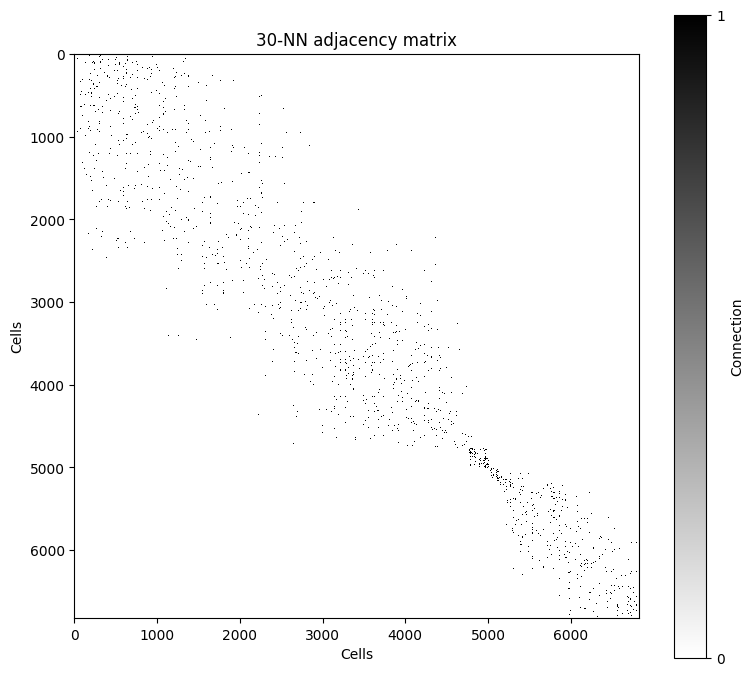

Adjacency matrix: 6,825 × 6,825
Directed edges: 204,750


In [37]:
from sklearn.neighbors import kneighbors_graph

adjacency = kneighbors_graph(
    pc_scores[:, :20],
    n_neighbors=30,
    mode="connectivity",
    metric="euclidean",
    include_self=False,
)

order = np.argsort(pc_scores[:, 0])
adjacency_plot = adjacency[order][:, order].astype(np.uint8).toarray()

fig, ax = plt.subplots(figsize=(8, 7))
heatmap = ax.imshow(adjacency_plot, cmap="binary", vmin=0, vmax=1,
                    interpolation="nearest")
ax.set(title="30-NN adjacency matrix", xlabel="Cells",
       ylabel="Cells")
fig.colorbar(heatmap, ax=ax, ticks=[0, 1], label="Connection")
plt.tight_layout()
plt.show()

print(f"Adjacency matrix: {adjacency.shape[0]:,} × {adjacency.shape[1]:,}")
print(f"Directed edges: {adjacency.nnz:,}")

Euclidean distance is appropriate because nearby cells in PCA space have similar patterns of normalized, log-transformed gene expression. It provides a direct measure of how close cells are based on their positions across the top 20 principal components. Since PCA captures the major sources of variation in the gene-expression data, this allows the nearest-neighbor graph to capture similarities between cells based on the main patterns of variation.

# Q4

In [38]:
import networkx as nx

undirected_adjacency = adjacency.maximum(adjacency.T)
graph = nx.from_scipy_sparse_array(undirected_adjacency)
communities = nx.community.louvain_communities(graph, resolution=1, seed=42)

louvain_ids = np.zeros(len(counts), dtype=int)
for cluster, cells in enumerate(communities, start=1):
    louvain_ids[list(cells)] = cluster

n_louvain = len(communities)
print(f"Louvain clusters: {n_louvain}")
print(f"K-means clusters: {best_k}")

Louvain clusters: 10
K-means clusters: 2


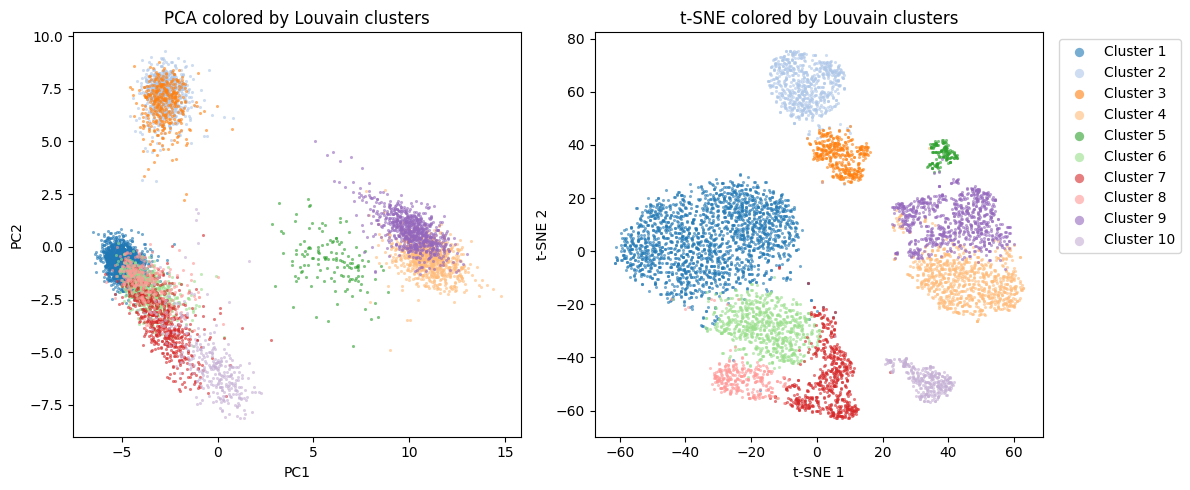

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = plt.get_cmap("tab20")

for cluster in range(1, n_louvain + 1):
    mask = louvain_ids == cluster
    axes[0].scatter(pc_scores[mask, 0], pc_scores[mask, 1],
                    s=5, alpha=0.6, linewidths=0,
                    color=colors(cluster - 1), label=f"Cluster {cluster}")
    axes[1].scatter(embedding[mask, 0], embedding[mask, 1],
                    s=5, alpha=0.6, linewidths=0,
                    color=colors(cluster - 1), label=f"Cluster {cluster}")

axes[0].set(title="PCA colored by Louvain clusters", xlabel="PC1", ylabel="PC2")
axes[1].set(title="t-SNE colored by Louvain clusters", xlabel="t-SNE 1", ylabel="t-SNE 2")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1), markerscale=3)
plt.tight_layout()
plt.show()

Louvain found 10 clusters (does not require choosing the number of clusters in advance), compared with 2 from K-means. It mostly divides the two broad K-means clusters into smaller groups that match the local groups visible in the t-SNE plot. Some of these clusters overlap in the first two PCs because clustering uses information from all 20 PCs. K-means groups cells by their distances to cluster centers, while Louvain uses connections between neighboring cells. Marker-gene analysis is still needed to determine whether these clusters actually represent different cell types.

## Q5a

I compared Louvain cluster 2 with all remaining cells using a two-sided Welch's t-test on the normalized, log-transformed expression values. Welch's test allows the two groups to have different variances. I corrected the p-values across all 500 genes using the Benjamini–Hochberg method. Among genes with adjusted p < 0.05 and higher expression in cluster 2, I selected the five with the largest positive t-statistics.

In [40]:
from scipy.stats import ttest_ind, false_discovery_control

chosen_cluster = 2
in_cluster = louvain_ids == chosen_cluster
expression_in = log_expression.loc[in_cluster]
expression_out = log_expression.loc[~in_cluster]

t_stat, p_value = ttest_ind(expression_in, expression_out, axis=0, equal_var=False)
p_value = np.nan_to_num(p_value, nan=1.0)

deg_results = pd.DataFrame({
    "gene": log_expression.columns,
    "mean_in": expression_in.mean().to_numpy(),
    "mean_out": expression_out.mean().to_numpy(),
    "t_stat": t_stat,
    "p_value": p_value,
    "adjusted_p": false_discovery_control(p_value, method="bh"),
})
top5 = deg_results.loc[
    (deg_results["adjusted_p"] < 0.05) & (deg_results["t_stat"] > 0)
].sort_values("t_stat", ascending=False).head(5)

print(f"Cluster {chosen_cluster}: {in_cluster.sum():,} cells; other cells: {(~in_cluster).sum():,}")
print(top5.to_string(index=False, float_format=lambda x: f"{x:.3g}"))

Cluster 2: 684 cells; other cells: 6,141
    gene  mean_in  mean_out  t_stat  p_value  adjusted_p
    IGKC     3.63     0.244     179        0           0
    CD74     3.96      1.68     132        0           0
 HLA-DRA     3.22      1.24    99.8        0           0
   CD79A     1.93     0.177    84.9        0           0
HLA-DPA1      2.3     0.655    83.3        0           0


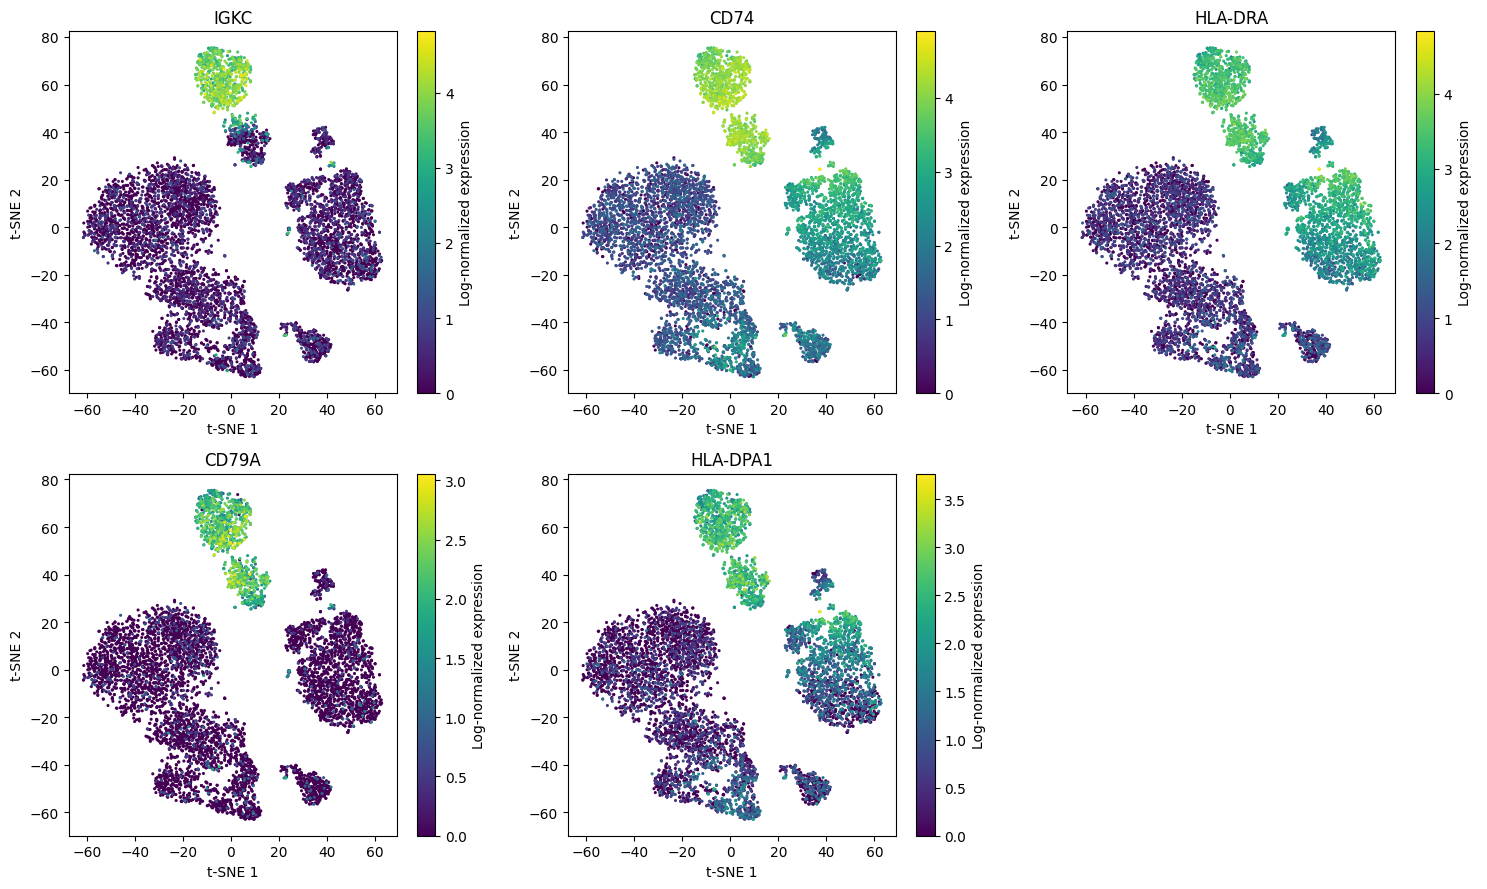

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, gene in zip(axes.flat, top5["gene"]):
    expression = log_expression[gene].to_numpy()
    order = np.argsort(expression)
    points = ax.scatter(embedding[order, 0], embedding[order, 1],
                        c=expression[order], cmap="viridis", s=5, linewidths=0)
    ax.set(title=gene, xlabel="t-SNE 1", ylabel="t-SNE 2")
    fig.colorbar(points, ax=ax, label="Log-normalized expression")

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

## Q5b

Cluster 2 most likely represents B cells. CD79A is involved in the B-cell receptor, while IGKC is related to immunoglobulins, which supports a B-cell identity. CD74, HLA-DRA, and HLA-DPA1 are involved in MHC class II antigen presentation, which is also consistent with B-cell function. Overall, these genes provide evidence that Cluster 2 is likely made up of B cells, although they do not tell us the specific B-cell subtype.

## Q5c

The Wilcoxon rank-sum test (Mann–Whitney U test) would be a good alternative. The expression data are sparse, with 42.58% zero values, and the counts are right-skewed. Unlike the t-test, this test does not assume that the expression values are normally distributed and instead compares the ranks of expression between the selected cluster and the remaining cells. Because many cells have the same expression value, especially zeros, a tie correction should be used. The resulting p-values should also be adjusted for multiple testing.

## Q6a

Let $Z_t$ denote the hidden state of bin $t$, where
$Z_t \in \{N,A\}$, and let $X_t$ denote the observed expression,
where $X_t \in \{L,H\}$.

The joint distribution of the hidden states and observations is

$$
P(Z_1,Z_2,Z_3,Z_4,X_1,X_2,X_3,X_4)
=
P(Z_1)
\prod_{t=2}^{4}P(Z_t\mid Z_{t-1})
\prod_{t=1}^{4}P(X_t\mid Z_t).
$$

For four bins, this can be written explicitly as

$$
\begin{aligned}
&P(Z_1,Z_2,Z_3,Z_4,X_1,X_2,X_3,X_4)\\
&=P(Z_1)
P(Z_2\mid Z_1)
P(Z_3\mid Z_2)
P(Z_4\mid Z_3)\\
&\quad\times
P(X_1\mid Z_1)
P(X_2\mid Z_2)
P(X_3\mid Z_3)
P(X_4\mid Z_4).
\end{aligned}
$$

### Conditional-independence assumptions

**Transition assumption:** The current hidden state depends only on the previous hidden state:

$$
P(Z_t\mid Z_1,\ldots,Z_{t-1})
=
P(Z_t\mid Z_{t-1}).
$$

In other words, the state of the current bin only depends on the state of the previous bin.

**Emission assumption:** Each observation depends only on its corresponding hidden state:

$$
P(X_t\mid Z_1,\ldots,Z_4,X_1,\ldots,X_{t-1})
=
P(X_t\mid Z_t).
$$

In other words, the observed expression level of a bin only depends on that bin's hidden state.

The initial probabilities are

$$
P(Z_1=N)=0.5,
\qquad
P(Z_1=A)=0.5,
$$

and the transition probabilities are

$$
P(N\mid N)=0.9,\qquad P(A\mid N)=0.1,
$$

$$
P(N\mid A)=0.1,\qquad P(A\mid A)=0.9.
$$

The emission probabilities are

$$
P(H\mid N)=0.2,\qquad P(L\mid N)=0.8,
$$

$$
P(H\mid A)=0.8,\qquad P(L\mid A)=0.2.
$$

# Q6b

The observed expression sequence is

$$
(X_1,X_2,X_3,X_4)=(H,H,L,H).
$$

We calculate the joint probability for each possible hidden-state sequence using

$$
P(Z_1,Z_2,Z_3,Z_4,X_1,X_2,X_3,X_4)
=
P(Z_1)
\prod_{t=2}^{4}P(Z_t\mid Z_{t-1})
\prod_{t=1}^{4}P(X_t\mid Z_t).
$$

### Hidden-state sequence: $(A,A,A,A)$

The initial probability is $P(Z_1=A)=0.5.$

The transition probabilities are

$$
P(Z_2=A\mid Z_1=A)=0.9,
$$

$$
P(Z_3=A\mid Z_2=A)=0.9,
$$

$$
P(Z_4=A\mid Z_3=A)=0.9.
$$

The emission probabilities for the observations $(H,H,L,H)$ are

$$
P(X_1=H\mid Z_1=A)=0.8,
$$

$$
P(X_2=H\mid Z_2=A)=0.8,
$$

$$
P(X_3=L\mid Z_3=A)=0.2,
$$

$$
P(X_4=H\mid Z_4=A)=0.8.
$$

Therefore,

$$
\begin{aligned}
P(AAAA,HHLH)
&=
P(A)
P(A\mid A)
P(A\mid A)
P(A\mid A)\\
&\quad\times
P(H\mid A)
P(H\mid A)
P(L\mid A)
P(H\mid A)\\
&=(0.5)(0.9)(0.9)(0.9)
(0.8)(0.8)(0.2)(0.8)\\
&=\boxed{0.0373248}.
\end{aligned}
$$

### Hidden-state sequence: $(A,A,N,A)$

The initial probability is $P(Z_1=A)=0.5.$

The transition probabilities are

$$
P(Z_2=A\mid Z_1=A)=0.9,
$$

$$
P(Z_3=N\mid Z_2=A)=0.1,
$$

$$
P(Z_4=A\mid Z_3=N)=0.1.
$$

The emission probabilities are

$$
P(X_1=H\mid Z_1=A)=0.8,
$$

$$
P(X_2=H\mid Z_2=A)=0.8,
$$

$$
P(X_3=L\mid Z_3=N)=0.8,
$$

$$
P(X_4=H\mid Z_4=A)=0.8.
$$

Therefore,

$$
\begin{aligned}
P(AANA,HHLH)
&=
P(A)
P(A\mid A)
P(N\mid A)
P(A\mid N)\\
&\quad\times
P(H\mid A)
P(H\mid A)
P(L\mid N)
P(H\mid A)\\
&=(0.5)(0.9)(0.1)(0.1)
(0.8)(0.8)(0.8)(0.8)\\
&=\boxed{0.0018432}.
\end{aligned}
$$

### Which sequence has the larger probability?

$$
0.0373248 > 0.0018432
$$

Therefore,

$$
\boxed{(A,A,A,A)\text{ has the larger joint probability.}}
$$

Even though the third observation is low expression ($L$), it can still be assigned to an amplified state ($A$). This is because $P(L\mid A)=0.2,$ so there is still a 20\% probability of observing low expression when the hidden state is amplified, so not deterministic.

Although $P(L\mid N)=0.8$ makes $N$ more likely for the third bin based only on the emission, the sequence $(A,A,N,A)$ requires two unlikely state transitions:
$P(N\mid A)=0.1$ and $P(A\mid N)=0.1.$

In contrast, the sequence $(A,A,A,A)$ has $P(A\mid A)=0.9$ for all three transitions. Therefore, the transition probabilities make $(A,A,A,A)$ more likely overall.

### Joint vs. posterior probability

The probabilities calculated above are joint probabilities.

For example, $P(AAAA,HHLH)=0.0373248$ is the probability of both the hidden-state sequence $AAAA$ and the observed sequence $HHLH$.

It is not $P(AAAA\mid HHLH),$ which would be the posterior probability of the hidden sequence $AAAA$ given that we observed $HHLH$.

The posterior probability would be calculated as

$$
P(AAAA\mid HHLH)
=
\frac{P(AAAA,HHLH)}
{P(HHLH)}.
$$

Thus, the values $0.0373248$ and $0.0018432$ are joint probabilities.

# Q6c

Sorting the bins by expression would change the order of the bins. For example, sorting (H,H,L,H) from low to high would give (L,H,H,H). However, the HMM assumes that neighboring bins are next to each other on the chromosome, so keeping the original genomic order is important.
If we sort the bins by expression, bins with similar expression levels could be placed next to each other even if they are far apart on the chromosome. Since the HMM favors staying in the same hidden state, this could create artificial stretches of neutral or amplified states. This would change the inferred hidden states and potentially the boundaries between regions. Therefore, the bins should be kept in their original genomic order when applying the HMM.

# Q6d

The probability of staying in the same state is $q$, and the probability of switching states is $1-q$, where $0<q<1$.

For $(A,A,A,A)$, all three transitions stay in the same state:

$$
\begin{aligned}
P(AAAA,HHLH)
&=(0.5)(q)(q)(q)(0.8)(0.8)(0.2)(0.8)\\
&=0.0512q^3.
\end{aligned}
$$

For $(A,A,N,A)$, there is one stay and two switches:

$$
\begin{aligned}
P(AANA,HHLH)
&=(0.5)(q)(1-q)(1-q)(0.8)(0.8)(0.8)(0.8)\\
&=0.2048q(1-q)^2.
\end{aligned}
$$

For $(A,A,A,A)$ to have the larger joint probability, we need

$$
0.0512q^3>0.2048q(1-q)^2.
$$

Dividing by $0.0512q$, which is positive, gives

$$
q^2>4(1-q)^2.
$$

Since both $q$ and $1-q$ are positive, taking square roots gives

$$
q>2(1-q)
\quad\Rightarrow\quad
3q>2
\quad\Rightarrow\quad
\boxed{\frac{2}{3}<q<1}.
$$

At $q=2/3$, the two sequences have equal joint probability. For $0<q<2/3$, $(A,A,N,A)$ has the larger joint probability.

A larger $q$ means that neighboring bins are more likely to have the same copy-number state. When $q>\frac{2}{3}$, the model favors keeping the bins continuously amplified, even though the third bin has low expression. When $q<\frac{2}{3}$, the sequence with a neutral third bin has a higher probability when comparing these two sequences. This comparison only considers these two possible sequences and does not tell us which sequence is most likely among all possible hidden-state sequences.

# Q7: PRML Problem 9.4

We want to use EM to maximize the posterior distribution

$$
p(\theta\mid\mathbf X)
$$

Starting from Equation (9.29),

$$
\ln p(\mathbf X\mid\theta)
=
\ln\left\{
\sum_{\mathbf Z}p(\mathbf X,\mathbf Z\mid\theta)
\right\}.
$$

Using Bayes' rule,

$$
p(\mathbf Z\mid\mathbf X,\theta)
=
\frac{p(\mathbf X,\mathbf Z\mid\theta)}
{p(\mathbf X\mid\theta)}.
$$

Therefore,

$$
p(\mathbf X,\mathbf Z\mid\theta)
=
p(\mathbf Z\mid\mathbf X,\theta)p(\mathbf X\mid\theta).
$$

For the EM algorithm, we use $\theta^{\mathrm{old}}$ to calculate the posterior distribution of the latent variables:

$$
p(\mathbf Z\mid\mathbf X,\theta^{\mathrm{old}}).
$$

We can multiply and divide inside the sum in Equation (9.29) by this distribution:

$$
\begin{aligned}
\ln p(\mathbf X\mid\theta)
&=
\ln\left\{
\sum_{\mathbf Z}
p(\mathbf Z\mid\mathbf X,\theta^{\mathrm{old}})
\frac{p(\mathbf X,\mathbf Z\mid\theta)}
{p(\mathbf Z\mid\mathbf X,\theta^{\mathrm{old}})}
\right\}.
\end{aligned}
$$

This gives the same E step as in the maximum likelihood case. In the E step, we calculate

$$
\boxed{
p(\mathbf Z\mid\mathbf X,\theta^{\mathrm{old}})
}
$$

because the prior $p(\theta)$ does not depend on the latent variable $\mathbf Z$.

For the M step, Bayes' rule gives

$$
p(\theta,\mathbf Z\mid\mathbf X)
=\frac{p(\mathbf X,\mathbf Z\mid\theta)p(\theta)}{p(\mathbf X)}.
$$

let $r(\mathbf Z)=p(\mathbf Z\mid\mathbf X,\theta^{\mathrm{old}})$, the distribution calculated in the E step. We define our MAP version of the $Q$-function as

$$
Q'(\theta,\theta^{\mathrm{old}})
=\sum_{\mathbf Z}r(\mathbf Z)\ln p(\theta,\mathbf Z\mid\mathbf X).
$$

Substituting Bayes' rule gives

$$
\begin{aligned}
Q'(\theta,\theta^{\mathrm{old}})
&=\sum_{\mathbf Z}r(\mathbf Z)
\left[\ln p(\mathbf X,\mathbf Z\mid\theta)
+\ln p(\theta)-\ln p(\mathbf X)\right]\\
&=\sum_{\mathbf Z}r(\mathbf Z)\ln p(\mathbf X,\mathbf Z\mid\theta)
+\ln p(\theta)-\ln p(\mathbf X),
\end{aligned}
$$

because $\sum_{\mathbf Z}r(\mathbf Z)=1$. The first term is the usual $Q$-function from Equation (9.30), so

$$
Q'(\theta,\theta^{\mathrm{old}})
=Q(\theta,\theta^{\mathrm{old}})+\ln p(\theta)+C,
$$

where $C=-\ln p(\mathbf X)$ does not depend on $\theta$.

To see why we maximize $Q'$, we apply Jensen's inequality to the sum over hidden variables:

$$
\begin{aligned}
\ln p(\theta\mid\mathbf X)
&=\ln\left\{\sum_{\mathbf Z}r(\mathbf Z)
\frac{p(\theta,\mathbf Z\mid\mathbf X)}{r(\mathbf Z)}\right\}\\
&\geq Q'(\theta,\theta^{\mathrm{old}})
-\sum_{\mathbf Z}r(\mathbf Z)\ln r(\mathbf Z).
\end{aligned}
$$

This bound equals the log posterior at $\theta=\theta^{\mathrm{old}}$. The last term is fixed during the M step, so maximizing $Q'$ increases or preserves the log posterior. Since $C$ is also constant, we maximize

$$
Q(\theta,\theta^{\mathrm{old}})+\ln p(\theta).
$$

Thus, the MAP version of the M step is

$$
\boxed{
\theta^{\mathrm{new}}
=
\arg\max_{\theta}
\left[
Q(\theta,\theta^{\mathrm{old}})
+
\ln p(\theta)
\right].
}
$$

Therefore, the E step stays the same as in the maximum likelihood case because the prior $p(\theta)$ does not involve the latent variables $\mathbf Z$. The difference occurs in the M step, where we maximize the usual $Q$-function plus the log prior:

$$
\boxed{
Q(\theta,\theta^{\mathrm{old}})
+
\ln p(\theta)
}
$$

instead of just $Q(\theta,\theta^{\mathrm{old}})$.